Starting simulation at t=0. s for a duration of 10. ks
79.9284 s (0%) simulated in 10s, estimated 20m 41s remaining.
161.6359 s (1%) simulated in 20s, estimated 20m 17s remaining.
247.1012 s (2%) simulated in 30s, estimated 19m 44s remaining.
0.3283486 ks (3%) simulated in 40s, estimated 19m 38s remaining.
0.4026723 ks (4%) simulated in 50s, estimated 19m 52s remaining.
0.4843484 ks (4%) simulated in 1m 0s, estimated 19m 39s remaining.
0.5684528 ks (5%) simulated in 1m 10s, estimated 19m 21s remaining.
0.6464488 ks (6%) simulated in 1m 20s, estimated 19m 18s remaining.
0.7299677 ks (7%) simulated in 1m 30s, estimated 19m 3s remaining.
0.8142541 ks (8%) simulated in 1m 40s, estimated 18m 48s remaining.
0.8919868 ks (8%) simulated in 1m 50s, estimated 18m 43s remaining.
0.9744909 ks (9%) simulated in 2m 0s, estimated 18m 31s remaining.
1.0572766 ks (10%) simulated in 2m 10s, estimated 18m 20s remaining.
1.1384261 ks (11%) simulated in 2m 20s, estimated 18m 14s remaining.
1.2202906 ks (12

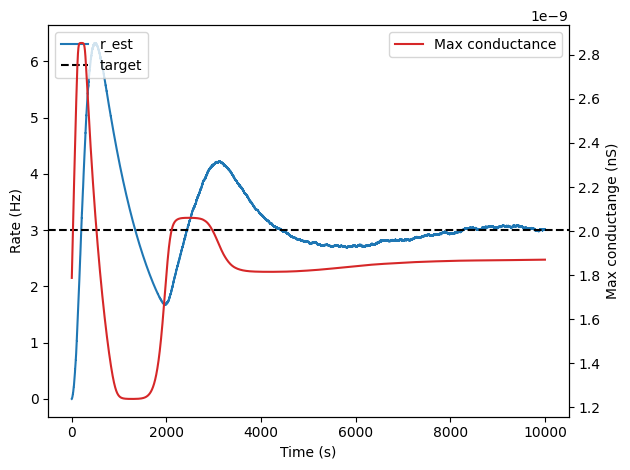

In [ ]:
from brian2 import *

start_scope()
defaultclock.dt = 0.1*ms

V_L = -70*mV
V_thr = -50*mV
V_reset = -55*mV
V_E = 0*mV

C_m_E = 0.5*nF
g_m_E = 10*nS
tau_AMPA = 8*ms

tau_HSP = 1000*second
target_rate = 3*Hz

tau_ins_AMPA_E = 500*second
tau_int_AMPA_E = 500*second

eqs_E = '''
dv/dt = (-g_m_E*(v - V_L) - I_syn)/C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext : amp

I_AMPA_ext = g_AMPA_ext_E * k_AMPA_E_hsp * (v - V_E) * s_AMPA_ext : amp

ds_AMPA_ext/dt = -s_AMPA_ext/tau_AMPA : 1

dx_spike/dt = -x_spike/tau_HSP : 1
r_est = x_spike/tau_HSP : Hz

# HSP scaling variables
dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
            - k_AMPA_E_hsp * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

'''

P = NeuronGroup(1, eqs_E,
                threshold='v > V_thr',
                reset='v = V_reset; x_spike += 1.',
                refractory=2*ms,
                method='euler')

P.v = V_L
P.k_AMPA_E_hsp = 0.275  

g_AMPA_ext_E = 6.5*nS

rate_in = 10*Hz  
inp = PoissonGroup(20, rates=rate_in)

S = Synapses(inp, P, model='w:1', on_pre='s_AMPA_ext += w')
S.connect()
S.w = 1.0

# Monitors
mon = StateMonitor(P, ['v', 'r_est', 'k_AMPA_E_hsp'], record=True, dt=100*ms)
sp = SpikeMonitor(P)

# Run long enough that HSP can act
run(10000*second, report='text')

# Quick plot
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots()
ax1.plot(mon.t/second, mon.r_est[0]/Hz, label='r_est')
ax1.axhline(target_rate/Hz, color='k', linestyle='--', label='target')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Rate (Hz)')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(mon.t/second, mon.k_AMPA_E_hsp[0]*g_AMPA_ext_E, color='tab:red', label='Max conductance')
ax2.set_ylabel('Max conductange (nS)')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


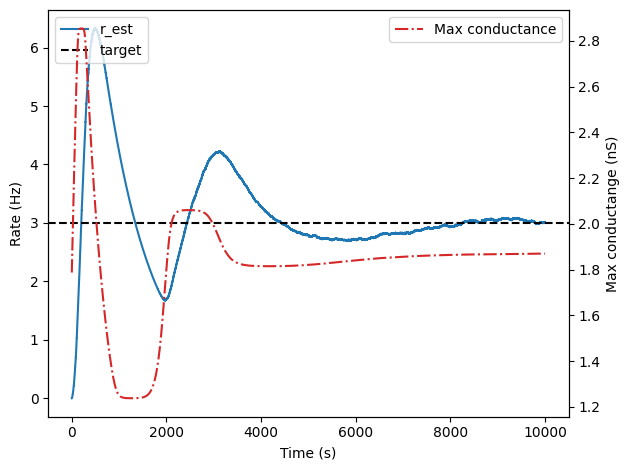

In [14]:
fig, ax1 = plt.subplots()
ax1.plot(mon.t/second, mon.r_est[0]/Hz,linestyle='-', label='r_est')
ax1.axhline(target_rate/Hz, color='k', linestyle='--', label='target')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Rate (Hz)')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(mon.t/second, mon.k_AMPA_E_hsp[0]*g_AMPA_ext_E*10**9,linestyle='-.', color='tab:red', label='Max conductance')
ax2.set_ylabel('Max conductange (nS)')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()